# Convolution, receptive fields, and transfer

A fully connected network treats an image as an unordered list of pixels. It does not know that
neighbouring pixels belong together, or that a shoe is still a shoe when it moves three pixels
to the left. Convolutional networks build both facts in, using the same two ideas the visual
system uses: **local receptive fields** and the **same detector repeated across space**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from scipy.signal import correlate2d
from skimage import data, transform

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10,
})
device = "cuda" if torch.cuda.is_available() else "cpu"
_ = torch.manual_seed(0)
print("device:", device)

device: cuda


## Convolution by hand

A **kernel** is a small grid of weights. Slide it over the image; at each position, multiply
the overlapping pixels by the weights and sum. Strictly this is *cross-correlation* (true
convolution flips the kernel first), but deep learning libraries use the word convolution for
it, and for learned kernels the distinction does not matter.

$$(I \star K)[i, j] = \sum_{u, v} I[i + u,\, j + v]\, K[u, v]$$

matches scipy: True


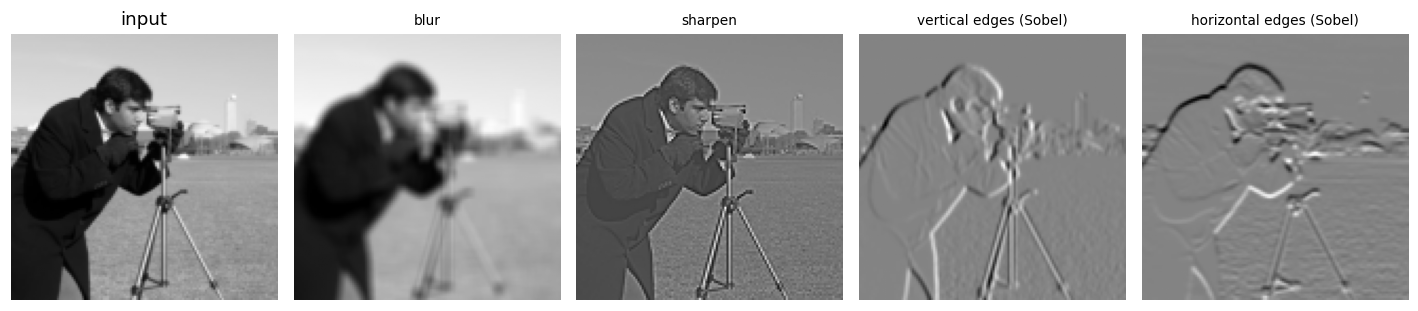

In [2]:
def conv2d(image, kernel):
    kh, kw = kernel.shape
    out = np.zeros((image.shape[0] - kh + 1, image.shape[1] - kw + 1))
    for i in range(out.shape[0]):
        for j in range(out.shape[1]):
            out[i, j] = np.sum(image[i:i + kh, j:j + kw] * kernel)
    return out

img = transform.resize(data.camera(), (128, 128), anti_aliasing=True)
kernels = {
    "blur": np.ones((5, 5)) / 25,
    "sharpen": np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]]),
    "vertical edges (Sobel)": np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]]),
    "horizontal edges (Sobel)": np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]),
}
print("matches scipy:", np.allclose(conv2d(img, kernels["sharpen"]),
                                    correlate2d(img, kernels["sharpen"], mode="valid")))

fig, axes = plt.subplots(1, 5, figsize=(13, 2.9))
axes[0].imshow(img, cmap="gray"); axes[0].set_title("input")
for ax, (name, k) in zip(axes[1:], kernels.items()):
    ax.imshow(conv2d(img, k), cmap="gray")
    ax.set_title(name, fontsize=9)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

Each output pixel depends only on a small patch of the input, its **receptive field**, and the
same kernel is applied everywhere. An edge detector that works in the top-left works in the
bottom-right too.

## Receptive fields in V1

Hubel and Wiesel found that simple cells in primary visual cortex respond to oriented edges
and bars at a particular position. Their receptive fields are well described by **Gabor
functions**: a sinusoidal grating under a Gaussian envelope. A bank of Gabor kernels at
different orientations is a model of V1, and convolving with it gives an orientation-specific
response map, one per orientation.

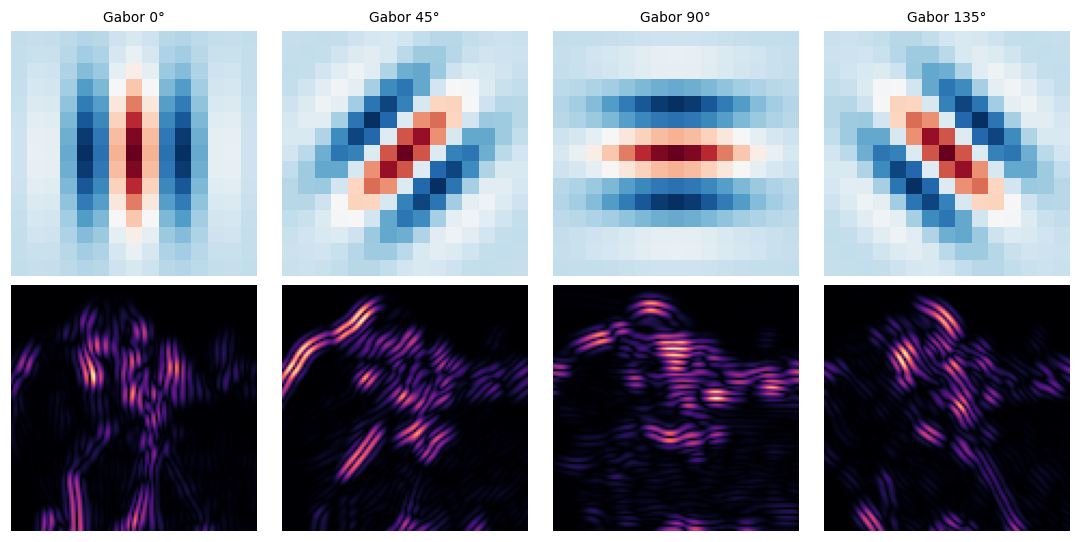

In [3]:
def gabor(theta, size=15, wavelength=6, sigma=3):
    r = np.arange(size) - size // 2
    x, y = np.meshgrid(r, r)
    xr = x * np.cos(theta) + y * np.sin(theta)
    g = np.exp(-(x ** 2 + y ** 2) / (2 * sigma ** 2)) * np.cos(2 * np.pi * xr / wavelength)
    return g - g.mean()

thetas = np.deg2rad([0, 45, 90, 135])
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for j, th in enumerate(thetas):
    k = gabor(th)
    axes[0, j].imshow(k, cmap="RdBu_r")
    axes[0, j].set_title(f"Gabor {np.rad2deg(th):.0f}°", fontsize=9)
    axes[1, j].imshow(np.abs(correlate2d(img, k, mode="valid")), cmap="magma")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

A CNN is not told to use Gabors. As we will see, it learns something similar from data.

## Fashion-MNIST: MLP versus CNN

Fashion-MNIST has 70,000 grey-scale 28×28 images of clothing in 10 classes. It is a drop-in
replacement for handwritten digits that is hard enough to separate good models from bad.

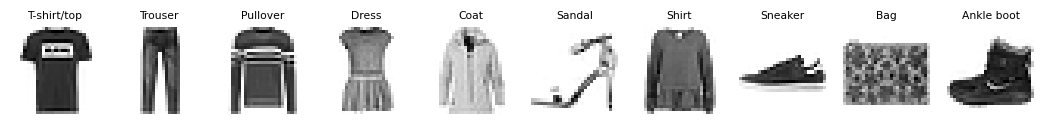

In [4]:
tf = torchvision.transforms.ToTensor()
train_set = torchvision.datasets.FashionMNIST("data", train=True, download=True, transform=tf)
test_set = torchvision.datasets.FashionMNIST("data", train=False, download=True, transform=tf)
classes = train_set.classes

X_train = train_set.data.float().div(255).unsqueeze(1)
y_train = train_set.targets
X_test = test_set.data.float().div(255).unsqueeze(1)
y_test = test_set.targets

fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))
for c, ax in enumerate(axes):
    ax.imshow(X_train[y_train == c][0, 0], cmap="gray_r")
    ax.set_title(classes[c], fontsize=7)
    ax.axis("off")
plt.show()

Two models with a similar number of parameters. The MLP flattens the image; the CNN keeps it as
a 2D grid and uses two convolution-pooling stages.

- `Conv2d(1, 16, 5)` learns 16 kernels of size 5×5.
- `ReLU` is the activation from notebook 4.
- `MaxPool2d(2)` keeps the largest value in each 2×2 block, halving resolution and making the
  output tolerant to small shifts.
- Finally a linear layer reads out the class.

In [5]:
mlp = nn.Sequential(nn.Flatten(), nn.Linear(784, 81), nn.ReLU(), nn.Linear(81, 10))

cnn = nn.Sequential(
    nn.Conv2d(1, 16, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2),   # 16 × 14 × 14
    nn.Conv2d(16, 32, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2),  # 32 × 7 × 7
    nn.Flatten(), nn.Linear(32 * 7 * 7, 32), nn.ReLU(), nn.Linear(32, 10))

def n_params(m):
    return sum(p.numel() for p in m.parameters())

print(f"MLP parameters: {n_params(mlp):,}")
print(f"CNN parameters: {n_params(cnn):,}")

MLP parameters: 64,405
CNN parameters: 63,786


In [6]:
def fit(model, X, y, epochs=5, lr=1e-3, batch=128, params=None):
    model.to(device)
    opt = torch.optim.Adam(params if params is not None else model.parameters(), lr=lr)
    n = len(X)
    for epoch in range(epochs):
        model.train()
        perm = torch.randperm(n)
        for i in range(0, n, batch):
            idx = perm[i:i + batch]
            xb, yb = X[idx].to(device), y[idx].to(device)
            opt.zero_grad()
            F.cross_entropy(model(xb), yb).backward()
            opt.step()
    return model

@torch.no_grad()
def accuracy(model, X, y):
    model.eval()
    preds = torch.cat([model(X[i:i + 2000].to(device)).argmax(1).cpu() for i in range(0, len(X), 2000)])
    return (preds == y).float().mean().item()

fit(mlp, X_train, y_train)
fit(cnn, X_train, y_train)
print(f"test accuracy  MLP: {accuracy(mlp, X_test, y_test):.3f}   CNN: {accuracy(cnn, X_test, y_test):.3f}")

test accuracy  MLP: 0.859   CNN: 0.886


With the same parameter budget, the CNN is clearly more accurate. Where the parameters go
differs: the two convolutional layers together have only about 13,000 weights, because each
kernel is shared across every position, and most of the CNN's parameters sit in the readout.

## What did it learn?

The first-layer kernels and the feature maps they produce for one image:

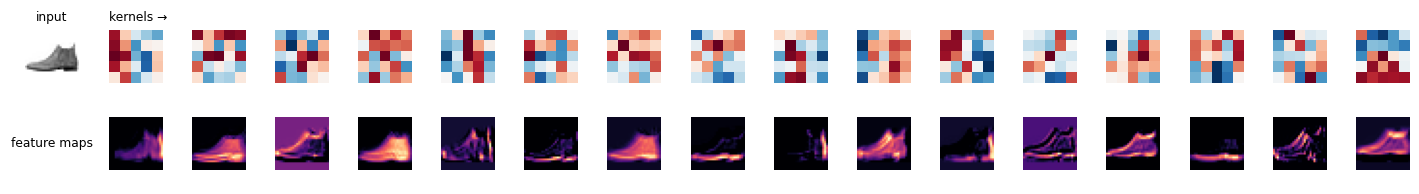

In [7]:
k1 = cnn[0].weight.detach().cpu()[:, 0]
x0 = X_test[:1].to(device)
with torch.no_grad():
    maps = cnn[1](cnn[0](x0))[0].cpu()

fig, axes = plt.subplots(2, 17, figsize=(13, 1.9))
axes[0, 0].imshow(X_test[0, 0], cmap="gray_r")
axes[0, 0].set_title("input", fontsize=8)
axes[1, 0].text(0.5, 0.5, "feature maps", ha="center", va="center", fontsize=8)
for j in range(16):
    lim = k1[j].abs().max()
    axes[0, j + 1].imshow(k1[j], cmap="RdBu_r", vmin=-lim, vmax=lim)
    axes[1, j + 1].imshow(maps[j], cmap="magma")
axes[0, 1].set_title("kernels →", fontsize=8, loc="left")
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

At 5×5 pixels and after five epochs the kernels are rough, but several have an oriented
light-dark structure, a coarse relative of the Gabors above, learned purely from the
classification objective. The feature maps are easier to read: some respond to the outline of
the boot, some to the sole, some to the filled interior.

## Shifts: why weight sharing matters

Move every test image a few pixels sideways. The MLP has a separate weight for every pixel, so
a shifted shoe activates entirely different weights. The CNN's shared kernels respond to the
feature wherever it is (*equivariance*), and pooling discards a little of the exact position.

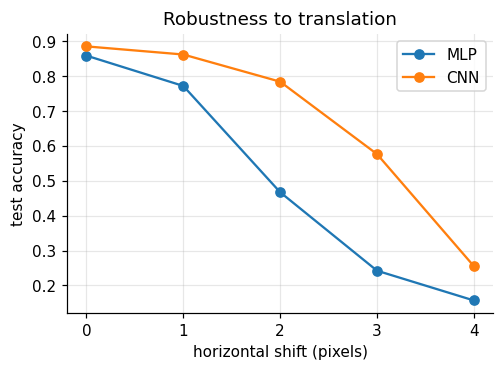

In [8]:
shifts = [0, 1, 2, 3, 4]
acc_mlp = [accuracy(mlp, torch.roll(X_test, s, dims=3), y_test) for s in shifts]
acc_cnn = [accuracy(cnn, torch.roll(X_test, s, dims=3), y_test) for s in shifts]

fig, ax = plt.subplots(figsize=(5, 3.3))
ax.plot(shifts, acc_mlp, "o-", label="MLP")
ax.plot(shifts, acc_cnn, "o-", label="CNN")
ax.set(xlabel="horizontal shift (pixels)", ylabel="test accuracy",
       title="Robustness to translation", xticks=shifts)
ax.grid(alpha=0.3)
ax.legend()
plt.show()

Both degrade, because Fashion-MNIST items are always centred during training, but the CNN
degrades far more slowly. Training on randomly shifted, flipped, or rotated copies (**data
augmentation**) closes much of the remaining gap by showing the network the variations it
should ignore.

## Transfer learning

Features learned for one task often help on another. Split the classes in two:

- **source task**: T-shirt, trouser, pullover, dress, coat (all training images);
- **target task**: sandal, shirt, sneaker, bag, ankle boot, with only **20 labelled images per
  class**.

We compare four ways to learn the target task from those 100 images:

1. train a fresh CNN **from scratch**;
2. copy the source network, **freeze the convolutional layers**, and train the fully connected
   layers;
3. freeze everything except a new output layer (**frozen up to the readout**);
4. **fine-tune** all layers of the copied network with a small learning rate.

In [9]:
def make_cnn(n_out):
    return nn.Sequential(
        nn.Conv2d(1, 16, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 5, padding=2), nn.ReLU(), nn.MaxPool2d(2),
        nn.Flatten(), nn.Linear(32 * 7 * 7, 32), nn.ReLU(), nn.Linear(32, n_out))

src_mask = y_train < 5
torch.manual_seed(0)
source = fit(make_cnn(5), X_train[src_mask], y_train[src_mask])

def target_split(n_per_class, seed):
    g = torch.Generator().manual_seed(seed)
    idx = torch.cat([torch.nonzero(y_train == c).squeeze(1)[torch.randperm(6000, generator=g)[:n_per_class]]
                     for c in range(5, 10)])
    return X_train[idx], y_train[idx] - 5

test_mask = y_test >= 5
Xt_test, yt_test = X_test[test_mask], y_test[test_mask] - 5

def from_source():
    m = make_cnn(5)
    m.load_state_dict(source.state_dict())
    m[-1] = nn.Linear(32, 5)          # new readout for the new classes
    return m

def frozen(up_to):
    m = from_source()
    for p in m[:up_to].parameters():
        p.requires_grad = False
    return m, [p for p in m.parameters() if p.requires_grad]

results = {"from scratch": [], "frozen conv": [], "frozen to readout": [], "fine-tuned": []}
for seed in range(5):
    Xs, ys = target_split(20, seed)
    torch.manual_seed(seed)
    results["from scratch"].append(accuracy(fit(make_cnn(5), Xs, ys, epochs=60, batch=32), Xt_test, yt_test))
    for name, up_to in [("frozen conv", 6), ("frozen to readout", 9)]:
        m, trainable = frozen(up_to)
        results[name].append(accuracy(fit(m, Xs, ys, epochs=60, batch=32, params=trainable), Xt_test, yt_test))
    results["fine-tuned"].append(accuracy(fit(from_source(), Xs, ys, epochs=60, batch=32, lr=3e-4),
                                          Xt_test, yt_test))

for k, v in results.items():
    print(f"{k:16s}: {np.mean(v):.3f} ± {np.std(v):.3f}  (5 random draws of 20 images per class)")

from scratch    : 0.882 ± 0.016  (5 random draws of 20 images per class)
frozen conv     : 0.908 ± 0.009  (5 random draws of 20 images per class)
frozen to readout: 0.547 ± 0.060  (5 random draws of 20 images per class)
fine-tuned      : 0.893 ± 0.003  (5 random draws of 20 images per class)


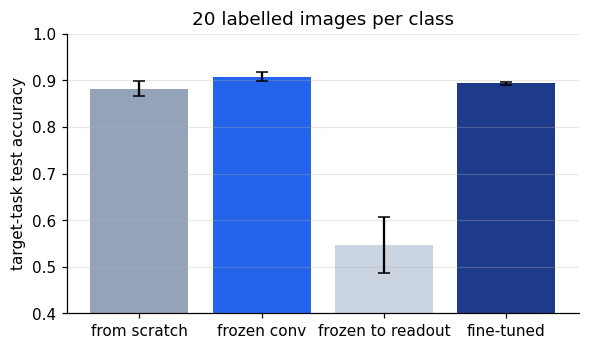

In [10]:
fig, ax = plt.subplots(figsize=(6, 3.3))
names = list(results)
ax.bar(names, [np.mean(results[k]) for k in names], yerr=[np.std(results[k]) for k in names],
       color=["#94a3b8", "#2563eb", "#cbd5e1", "#1e3a8a"], capsize=4)
ax.set(ylabel="target-task test accuracy", ylim=(0.4, 1), title="20 labelled images per class")
ax.grid(axis="y", alpha=0.3)
plt.show()

Two lessons, one small and one large.

The small one: reusing the frozen convolutional layers gives a modest but consistent gain over
training from scratch, with less variability across draws of the 100 training images. The gain
is small here because a tiny CNN already learns these 28×28 images well from 100 examples, and
fine-tuning everything with a small learning rate lands in between.

The large one: freezing *too much* is a disaster. The fully connected hidden layer was tuned to
separate T-shirts from pullovers, and its features do not separate sandals from sneakers.
Early layers learn general features (edges, textures), later layers learn task-specific ones,
so how much to transfer depends on how similar the tasks are. With natural images and networks
pretrained on millions of photos, the general features are far richer and transfer is much
more valuable, which is why ImageNet-pretrained networks are the usual starting point for small
image datasets, and popular models of the ventral visual stream.

## Summary

- Convolution slides one small kernel over the whole image: local receptive fields and shared
  weights.
- Gabor kernels model V1 simple cells; CNNs learn similar edge detectors on their own.
- Shared weights make CNNs more accurate with fewer parameters and more robust to shifts.
- Pooling and data augmentation add further tolerance to nuisance variation.
- Transfer learning reuses features from a data-rich task to learn a data-poor one; early
  layers transfer, late layers often do not.